# Basis-set energy convergence for C₂H₆

The hydrogenation reaction energy in `usecase1` came out far from experiment. Before blaming
the basis set, this experiment isolates **one variable**: for a single molecule (ethane), does
the *optimized* energy improve as the basis set grows?

Run a **method × basis** matrix: each cell is a full geometry optimization of C₂H₆, and
record the optimized total energy:

|            | HF | DFT-BLYP | DFT-B3LYP |
|------------|----|----------|-----------|
| **3-21G**    | | | |
| **6-31G***   | | | |
| **6-31G****  | | | |
| **6-311G**** | | | |

**What to expect:** within each *column* (fixed method, growing basis) the energy should go
**down**, because a bigger basis is more flexible, so the variational energy can only improve.

In [1]:
import sys
!{sys.executable} -m pip install --quiet matplotlib

DEPRECATION: Configuring installation scheme with distutils config files is deprecated and will no longer work in the near future. If you are using a Homebrew or Linuxbrew Python, please see discussion at https://github.com/Homebrew/homebrew-core/issues/76621


DEPRECATION: Configuring installation scheme with distutils config files is deprecated and will no longer work in the near future. If you are using a Homebrew or Linuxbrew Python, please see discussion at https://github.com/Homebrew/homebrew-core/issues/76621



[notice] A new release of pip is available: 24.2 -> 26.0.1
[notice] To update, run: python3.9 -m pip install --upgrade pip


In [2]:
import pyquick
import matplotlib.pyplot as plt

ETHANE = """
    C   0.0000   0.0000   0.7680
    C   0.0000   0.0000  -0.7680
    H   1.0192   0.0000   1.1573
    H  -0.5096   0.8826   1.1573
    H  -0.5096  -0.8826   1.1573
    H  -1.0192   0.0000  -1.1573
    H   0.5096   0.8826  -1.1573
    H   0.5096  -0.8826  -1.1573
"""

# columns = methods, rows = basis sets
METHODS = ['HF', 'BLYP', 'B3LYP']
LABELS  = {'HF': 'HF', 'BLYP': 'DFT-BLYP', 'B3LYP': 'DFT-B3LYP'}
BASES   = ['3-21G', '6-31G*', '6-31G**', '6-311G**']

In [3]:
## Run the matrix

energies = {m: {} for m in METHODS}

for method in METHODS:
    for basis in BASES:
        calc = pyquick.PyQuick(method=method, basis=basis, log=False)

        r = calc.geo_opt(ETHANE)
        energies[method][basis] = r.total_energy
        flag = 'converged' if r.converged else 'NOT CONVERGED'
        print(f'{LABELS[method]:10s} {basis:9s}  E = {r.total_energy}  ({flag})')

HF         3-21G      E = -78.7939479928894  (converged)
HF         6-31G*     E = -79.22875491476546  (converged)
HF         6-31G**    E = -79.23823491467843  (converged)
HF         6-311G**   E = -79.25178803222943  (converged)
DFT-BLYP   3-21G      E = -79.3334299729884  (converged)
DFT-BLYP   6-31G*     E = -79.76320205889843  (converged)
DFT-BLYP   6-31G**    E = -79.77147434108855  (converged)
DFT-BLYP   6-311G**   E = -79.79341744125571  (converged)


DFT-B3LYP  3-21G      E = -79.40063045405253  (converged)
DFT-B3LYP  6-31G*     E = -79.83040674691262  (converged)
DFT-B3LYP  6-31G**    E = -79.83872912795911  (converged)
DFT-B3LYP  6-311G**   E = -79.85726168903443  (converged)


In [4]:
# Tabulate
header = f"{'basis':10s}" + ''.join(f'{LABELS[m]:>14s}' for m in METHODS)
print(header)
print('-' * len(header))

for basis in BASES:
    row = f'{basis:10s}'
    for m in METHODS:
        e = energies[m][basis]
        row += f'{e:14.6f}'
    print(row)

basis                 HF      DFT-BLYP     DFT-B3LYP
----------------------------------------------------
3-21G         -78.793948    -79.333430    -79.400630
6-31G*        -79.228755    -79.763202    -79.830407
6-31G**       -79.238235    -79.771474    -79.838729
6-311G**      -79.251788    -79.793417    -79.857262


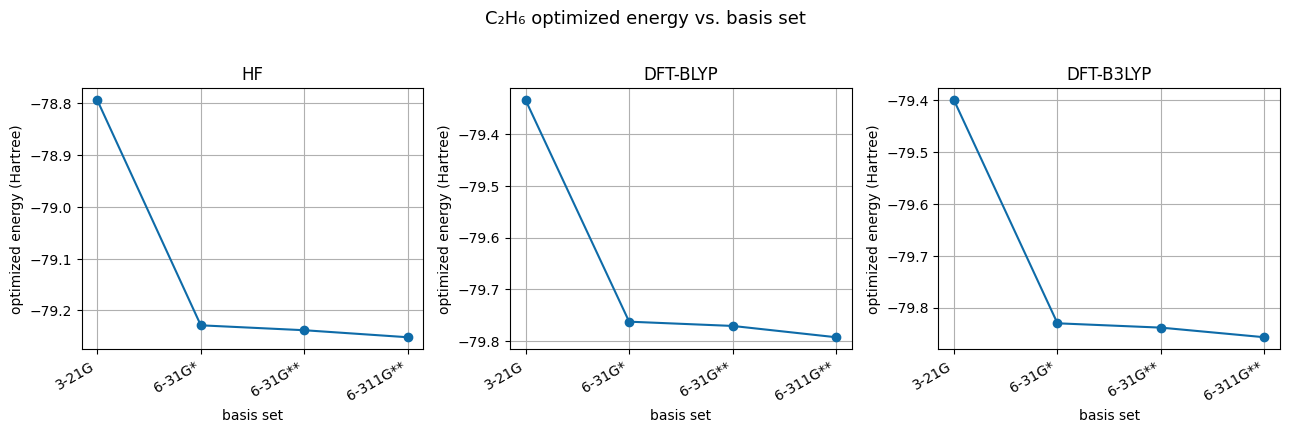

In [5]:
## Plot

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
x = range(len(BASES))

for ax, method in zip(axes, METHODS):
    ys = [energies[method][b] for b in BASES]
    ax.plot(x, ys, 'o-', color='#0E6BA8')
    ax.set_xticks(list(x))
    ax.set_xticklabels(BASES, rotation=30, ha='right')
    ax.set_title(LABELS[method])
    ax.set_xlabel('basis set')
    ax.set_ylabel('optimized energy (Hartree)')
    ax.grid(True)

fig.suptitle('C₂H₆ optimized energy vs. basis set', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
# reaction ene 